# Analyse Data

Analyze for ideal split:
- Count fairytales
- Count tokens per fairytale
    - BiLSTM
    - RoBERTa
- Count annotated spans per fairytale
- Look at percentage Label 1 & 2

In [1]:
import os
import json
import numpy as np
import pandas as pd
from spacy.lang.de import German
from math import gcd

In [2]:
INPUT_FILE = "../grimm_fairytales_annotated/vague_loc_after_iaa_29-9-26.json"

In [3]:
with open(INPUT_FILE, "r") as json_file:
    fairytales = json.load(json_file)

## Count Words

In [4]:
def count_words_per_fairytale(input_json):
    words_per_fairytale = {}

    for fairytale in input_json:
        word_count = 0
        text = fairytale["text"]
        words = text.split()
        word_count += len(words)

        words_per_fairytale[fairytale["khm"]] = word_count

    return words_per_fairytale

In [5]:
words_per_fairytale = count_words_per_fairytale(fairytales)
df_fairytale = pd.DataFrame.from_dict(words_per_fairytale, orient="index", columns=["word count"]).sort_index()
df_fairytale.index.name = "khm"
# dictionary mapping khm to text
khm_to_text = {fairytale["khm"]: fairytale["text"] for fairytale in fairytales}
df_fairytale["text"] = df_fairytale.index.map(khm_to_text)

display(df_fairytale)

,word count,text
khm,,
1,1291,"In den alten Zeiten, wo das Wünschen noch geho..."
2,891,Eine Katze hatte Bekanntschaft mit einer Maus ...
3,1771,Vor einem großen Walde lebte ein Holzhacker mi...
4,3418,"Ein Vater hatte zwei Söhne, davon war der älte..."
5,1009,"Es war einmal eine alte Geis, die hatte sieben..."
...,...,...
206,874,"Es war einmal ein Einsiedler, der lebte in ein..."
207,138,"Es hatte einmal ein Fuhrmann seinen Karren, de..."
208,311,Es war in einer großen Stadt ein altes Mütterc...


In [6]:
def sentence_length(df):
    nlp = German()  # contains tokenizer, no other SpaCy Pipeline Components
    nlp.add_pipe("sentencizer")
    for khm, row in df.iterrows():
        text = row["text"]
        sentences = list(nlp(text).sents)

        df.loc[khm, "count sentences"] = int(len(sentences))

        words_per_sentence = [len(sentence.text.split()) for sentence in sentences]
        df.loc[khm, "mean sentence length"] = np.round(np.mean(words_per_sentence))


In [7]:
sentence_length(df_fairytale)
df_fairytale.head()

,word count,text,count sentences,mean sentence length
khm,,,,
1,1291,"In den alten Zeiten, wo das Wünschen noch geho...",52.0,25.0
2,891,Eine Katze hatte Bekanntschaft mit einer Maus ...,49.0,19.0
3,1771,Vor einem großen Walde lebte ein Holzhacker mi...,67.0,26.0
4,3418,"Ein Vater hatte zwei Söhne, davon war der älte...",189.0,18.0
5,1009,"Es war einmal eine alte Geis, die hatte sieben...",50.0,20.0


## Label Distribution

In [8]:
def count_labels(input_json):
    labels_per_fairytale = {}

    for fairytale in input_json:
        khm = fairytale["khm"]

        total_labels = len(fairytale.get("label", []))
        count_fuzzy_loc = sum(1 for item in fairytale.get("label", [])
                              if item.get("labels", [None])[0] == "FUZZY_LOC")
        count_metaphoric_loc = sum(1 for item in fairytale.get("label", [])
                                   if item.get("labels", [None])[0] == "METAPHORIC_LOC")


        labels_per_fairytale[khm] = (total_labels, count_fuzzy_loc, count_metaphoric_loc)

    return labels_per_fairytale


In [9]:
counted_labels = count_labels(fairytales)

for khm, (total, fuzzy, metaphoric) in counted_labels.items():
    df_fairytale.loc[khm, "total labels"] = total
    df_fairytale.loc[khm, "fuzzy loc count"] = fuzzy
    df_fairytale.loc[khm, "metaphoric loc count"] = metaphoric

num_cols = df_fairytale.select_dtypes(include="number").columns
df_fairytale[num_cols] = df_fairytale[num_cols].astype(int)

df_fairytale.head()

,word count,text,count sentences,mean sentence length,total labels,fuzzy loc count,metaphoric loc count
khm,,,,,,,
1,1291,"In den alten Zeiten, wo das Wünschen noch geho...",52,25,49,42,7
2,891,Eine Katze hatte Bekanntschaft mit einer Maus ...,49,19,18,10,8
3,1771,Vor einem großen Walde lebte ein Holzhacker mi...,67,26,35,30,5
4,3418,"Ein Vater hatte zwei Söhne, davon war der älte...",189,18,80,76,4
5,1009,"Es war einmal eine alte Geis, die hatte sieben...",50,20,38,33,5


In [10]:
def simplify_ratio(a, b):
    if a == 0 and b == 0:
        return "0:0"
    if a == 0:
        return "0:1"
    if b == 0:
        return "1:0"

    divisor = gcd(a, b)
    return f"{a // divisor}:{b // divisor}"

df_fairytale["ratio fuzzy metaphoric"] = df_fairytale.apply(
    lambda row: simplify_ratio(
        row["fuzzy loc count"],
        row["metaphoric loc count"]
    ),
    axis=1
)

df_fairytale.head()

,word count,text,count sentences,mean sentence length,total labels,fuzzy loc count,metaphoric loc count,ratio fuzzy metaphoric
khm,,,,,,,,
1,1291,"In den alten Zeiten, wo das Wünschen noch geho...",52,25,49,42,7,6:1
2,891,Eine Katze hatte Bekanntschaft mit einer Maus ...,49,19,18,10,8,5:4
3,1771,Vor einem großen Walde lebte ein Holzhacker mi...,67,26,35,30,5,6:1
4,3418,"Ein Vater hatte zwei Söhne, davon war der älte...",189,18,80,76,4,19:1
5,1009,"Es war einmal eine alte Geis, die hatte sieben...",50,20,38,33,5,33:5


## Token BiLSTM

In [11]:
from dataset_preprocessing import load_dataset, annotate_dataset, create_token_documents

/home/pia/PycharmProjects/spatial_extraction_fairytales/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [12]:
dataset = load_dataset(INPUT_FILE)
docs, errors = annotate_dataset(dataset)
token_documents = create_token_documents(docs)

In [13]:
def count_token_per_fairytale(token_documents):
    for fairytale, token_document in zip(dataset.fairytales, token_documents):
        khm = fairytale.khm

        df_fairytale.loc[khm, "spaCy tokens"] = len(token_document.tokens)


In [14]:
count_token_per_fairytale(token_documents)

num_cols = df_fairytale.select_dtypes(include="number").columns
df_fairytale[num_cols] = df_fairytale[num_cols].astype(int)

df_fairytale.head()

,word count,text,count sentences,mean sentence length,total labels,fuzzy loc count,metaphoric loc count,ratio fuzzy metaphoric,spaCy tokens
khm,,,,,,,,,
1,1291,"In den alten Zeiten, wo das Wünschen noch geho...",52,25,49,42,7,6:1,1579
2,891,Eine Katze hatte Bekanntschaft mit einer Maus ...,49,19,18,10,8,5:4,1116
3,1771,Vor einem großen Walde lebte ein Holzhacker mi...,67,26,35,30,5,6:1,2055
4,3418,"Ein Vater hatte zwei Söhne, davon war der älte...",189,18,80,76,4,19:1,4293
5,1009,"Es war einmal eine alte Geis, die hatte sieben...",50,20,38,33,5,33:5,1201


## RoBERTa Token

In [15]:
from transformers import AutoTokenizer

In [16]:
TOKENIZER_NAME = "FacebookAI/xlm-roberta-large-finetuned-conll03-german"
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)

In [17]:
def count_token_per_fairytale_transformer(dataset, tokenizer):
    for fairytale in dataset.fairytales:

        # exclude special tokens, no warning for sequence > 512 token
        encoding = tokenizer(fairytale.text, add_special_tokens=False, truncation=False, verbose=False)

        df_fairytale.loc[fairytale.khm, "roBERTa tokens"] = len(encoding["input_ids"])

In [18]:
count_token_per_fairytale_transformer(dataset, tokenizer)

num_cols = df_fairytale.select_dtypes(include="number").columns
df_fairytale[num_cols] = df_fairytale[num_cols].astype(int)

df_fairytale.head()

,word count,text,count sentences,mean sentence length,total labels,fuzzy loc count,metaphoric loc count,ratio fuzzy metaphoric,spaCy tokens,roBERTa tokens
khm,,,,,,,,,,
1,1291,"In den alten Zeiten, wo das Wünschen noch geho...",52,25,49,42,7,6:1,1579,2019
2,891,Eine Katze hatte Bekanntschaft mit einer Maus ...,49,19,18,10,8,5:4,1116,1445
3,1771,Vor einem großen Walde lebte ein Holzhacker mi...,67,26,35,30,5,6:1,2055,2632
4,3418,"Ein Vater hatte zwei Söhne, davon war der älte...",189,18,80,76,4,19:1,4293,5401
5,1009,"Es war einmal eine alte Geis, die hatte sieben...",50,20,38,33,5,33:5,1201,1521


In [19]:
print(df_fairytale["word count"].sum())
print(df_fairytale["count sentences"].sum())
print(df_fairytale["total labels"].sum())
print(df_fairytale["fuzzy loc count"].sum())
print(df_fairytale["metaphoric loc count"].sum())

234325
10942
5688
4875
813


## Saving results

In [20]:
df_fairytale.to_csv("analysis_dataset.csv")

# Visualizing results

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import hvplot.pandas

In [45]:
df = pd.read_csv("analysis_dataset.csv", index_col="khm")
df = df.sort_index()

In [46]:
numeric_cols = [
    "word count",
    "count sentences",
    "mean sentence length",
    "total labels",
    "fuzzy loc count",
    "metaphoric loc count",
    "spaCy tokens",
    "roBERTa tokens",
]

df[numeric_cols] = df[numeric_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

## Text

#todo change to Histogram for better readability
#todo change to hvplot https://hvplot.holoviz.org/en/docs/latest/index.html for zooming plots

## Balkendiagramm Satzanzahl

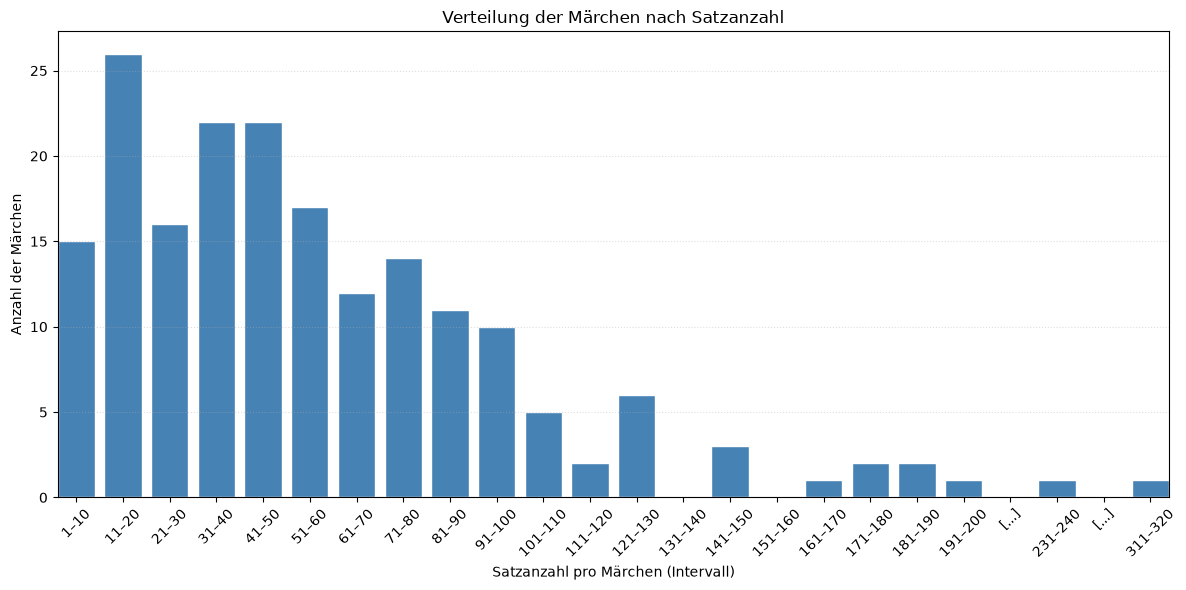

In [74]:
sentences = df["count sentences"].dropna()

bin_width = 10
max_sentences = int(sentences.max())

bins = np.arange(
    0,
    ((max_sentences // bin_width) + 1) * bin_width + bin_width,
    bin_width
)

labels = [
    f"{start + 1}–{start + bin_width}"
    for start in bins[:-1]
]

sentence_groups = pd.cut(
    sentences,
    bins=bins,
    labels=labels,
    right=True,
    include_lowest=True
)

# wichtig: leere Kategorien wegnehmen
sentence_groups = sentence_groups.cat.remove_unused_categories()
sentence_counts = sentence_groups.value_counts(sort=False)

present_labels = {str(k): int(v) for k, v in sentence_counts.items()}

display_labels = []
display_values = []

i = 0
while i < len(labels):
    label = labels[i]

    if label in present_labels:
        display_labels.append(label)
        display_values.append(present_labels[label])
        i += 1
        continue

    gap_start = i
    while i < len(labels) and labels[i] not in present_labels:
        i += 1
    gap_len = i - gap_start

    if gap_len == 1:
        display_labels.append(labels[gap_start])
        display_values.append(0)
    else:
        display_labels.append("[...]")
        display_values.append(0)

x = np.arange(len(display_labels))

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x, display_values, color="steelblue", edgecolor="white", width=0.8)

ax.set_xticks(x)
ax.set_xticklabels(display_labels, rotation=45)

ax.margins(x=0)
ax.set_xlabel("Satzanzahl pro Märchen (Intervall)")
ax.set_ylabel("Anzahl der Märchen")
ax.set_title("Verteilung der Märchen nach Satzanzahl")
ax.grid(axis="y", linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()

## Verteilung Satzanzahl

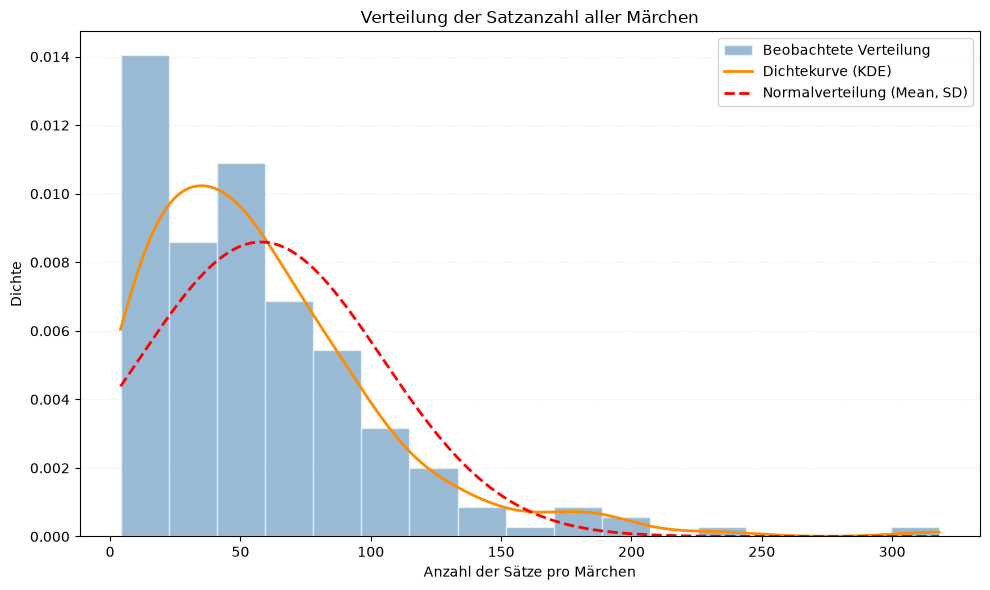

Anzahl Märchen: 189
Mittelwert: 57.89
Median: 49.00
Standardabweichung: 46.43
Schiefe: 1.89


In [39]:
from scipy.stats import gaussian_kde, norm, skew

values = sentences.to_numpy()

fig, ax = plt.subplots(figsize=(10, 6))

# Histogramm als relative Häufigkeit
ax.hist(
    values,
    bins="fd",
    density=True,
    alpha=0.55,
    color="steelblue",
    edgecolor="white",
    label="Beobachtete Verteilung"
)

# KDE: geglättete Schätzung der tatsächlichen Verteilung
x = np.linspace(values.min(), values.max(), 500)
kde = gaussian_kde(values)

ax.plot(
    x,
    kde(x),
    color="darkorange",
    linewidth=2,
    label="Dichtekurve (KDE)"
)

# Vergleichskurve einer Normalverteilung
mu = values.mean()
sigma = values.std(ddof=1)

ax.plot(
    x,
    norm.pdf(x, loc=mu, scale=sigma),
    color="red",
    linestyle="--",
    linewidth=2,
    label="Normalverteilung (Mean, SD)"
)

ax.set_xlabel("Anzahl der Sätze pro Märchen")
ax.set_ylabel("Dichte")
ax.set_title("Verteilung der Satzanzahl aller Märchen")
ax.legend()
ax.grid(axis="y", linestyle=":", alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Anzahl Märchen: {len(values)}")
print(f"Mittelwert: {values.mean():.2f}")
print(f"Median: {np.median(values):.2f}")
print(f"Standardabweichung: {values.std(ddof=1):.2f}")
print(f"Schiefe: {skew(values, bias=False):.2f}")

## Boxplot Median & Ausreißer Satzlänge

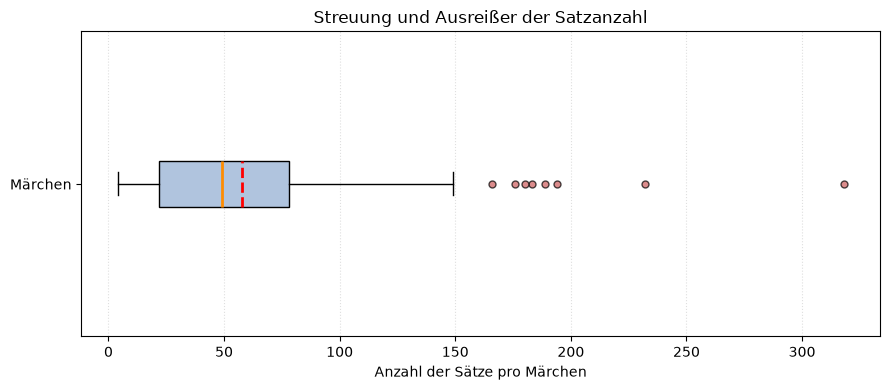

In [79]:

fig, ax = plt.subplots(figsize=(9, 4))

ax.boxplot(
    sentences.values,
    showmeans=True,
    meanline=True,
    patch_artist=True,
    boxprops={"facecolor": "lightsteelblue"},
    medianprops={"color": "darkorange", "linewidth": 2},
    meanprops={
        "color": "red",
        "linestyle": "--",
        "linewidth": 2
    },
    flierprops={
        "marker": "o",
        "markerfacecolor": "indianred",
        "markersize": 5,
        "alpha": 0.7
    },
    orientation="horizontal",
)

ax.set_xlabel("Anzahl der Sätze pro Märchen")
ax.set_title("Streuung und Ausreißer der Satzanzahl")
ax.set_yticks([1])
ax.set_yticklabels(["Märchen"])
ax.grid(axis="x", linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()

## Plot nach Split

In [81]:
from data_split import data_split_on_khm

In [83]:
ANALYSIS_PATH = "analysis_dataset.csv"
train_khm, val_khm, test_khm = data_split_on_khm(ANALYSIS_PATH, 42)

Train: [181, 30, 7, 77, 69, 62, 39, 29, 202, 162, 25, 178, 127, 10, 9, 31, 70, 75, 159, 192, 8, 179, 63, 175, 134, 74, 148, 197, 94, 2, 53, 145, 116, 99, 52, 79, 119, 37, 34, 136, 36, 130, 125, 101, 17, 173, 205, 48, 149, 32, 114, 146, 80, 26, 18, 97, 120, 38, 102, 45, 164, 121, 103, 144, 184, 83, 40, 86, 84, 50, 158, 61, 169, 166, 156, 15, 152, 160, 43, 132, 188, 60, 42, 118, 104, 72, 176, 191, 154, 58, 194, 90, 13, 65, 6, 98, 122, 85, 20, 67, 182, 107, 71, 208, 168, 131, 210, 155, 46, 92, 44, 89, 200, 195, 105, 161, 151, 135, 81, 49, 204, 199, 24, 14, 41, 59, 141, 27, 180, 157, 108, 142, 11, 100, 106, 163, 117, 133, 57, 170, 1, 198, 209, 23, 206, 172, 78, 207, 110]
Val: [28, 93, 150, 54, 177, 3, 109, 201, 64, 112, 193, 16, 189, 147, 56, 171, 124, 174, 35, 22, 111, 51]
Test: [4, 5, 12, 21, 33, 55, 73, 76, 87, 88, 115, 123, 128, 129, 153, 183, 185, 186]


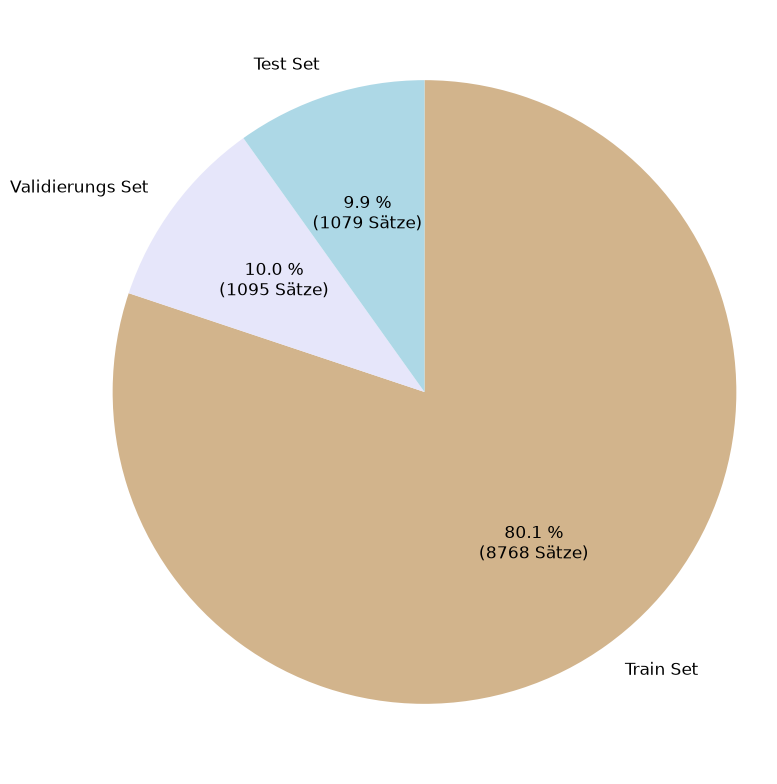

In [94]:
# Satzanzahl pro Part aufsummieren
part_sums = {
    "Train Set": df.loc[train_khm, "count sentences"].sum(),
    "Validierungs Set": df.loc[val_khm, "count sentences"].sum(),
    "Test Set": df.loc[test_khm, "count sentences"].sum(),
}

# Tortendiagramm
fig, ax = plt.subplots(figsize=(8, 8))

# setting font sizeto 30
plt.rcParams.update({'font.size': 12 })

colors = ["tan", "lavender", "lightblue"]

ax.pie(
    part_sums.values(),
    labels=part_sums.keys(),
    autopct=lambda pct: f"{pct:.1f} %\n({pct / 100 * sum(part_sums.values()):.0f} Sätze)",
    colors=colors,
    startangle=90,
    counterclock=False
)
#ax.set_title("Verteilung der Satzanzahl nach dem Data Split")
ax.axis("equal")

plt.tight_layout()
plt.show()

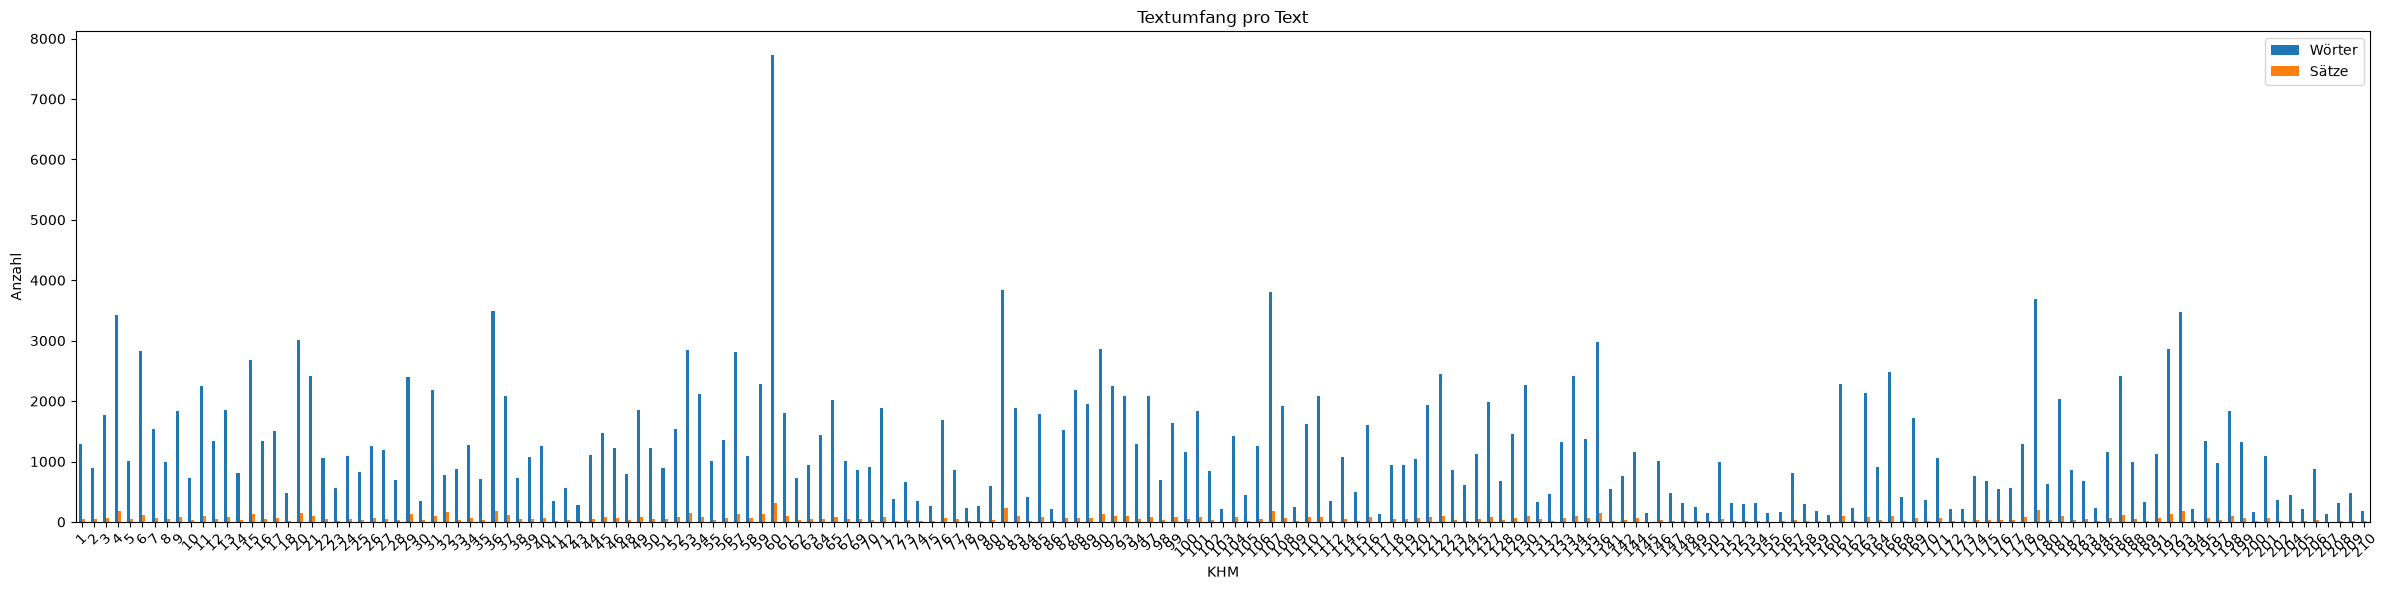

In [43]:
fig, ax = plt.subplots(figsize=(24, 6))

df[
    ["word count", "count sentences"]
].plot(
    kind="bar",
    ax=ax
)

ax.set_title("Textumfang pro Text")
ax.set_xlabel("KHM")
ax.set_ylabel("Anzahl")
ax.legend(["Wörter", "Sätze"])

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Mean Textlength

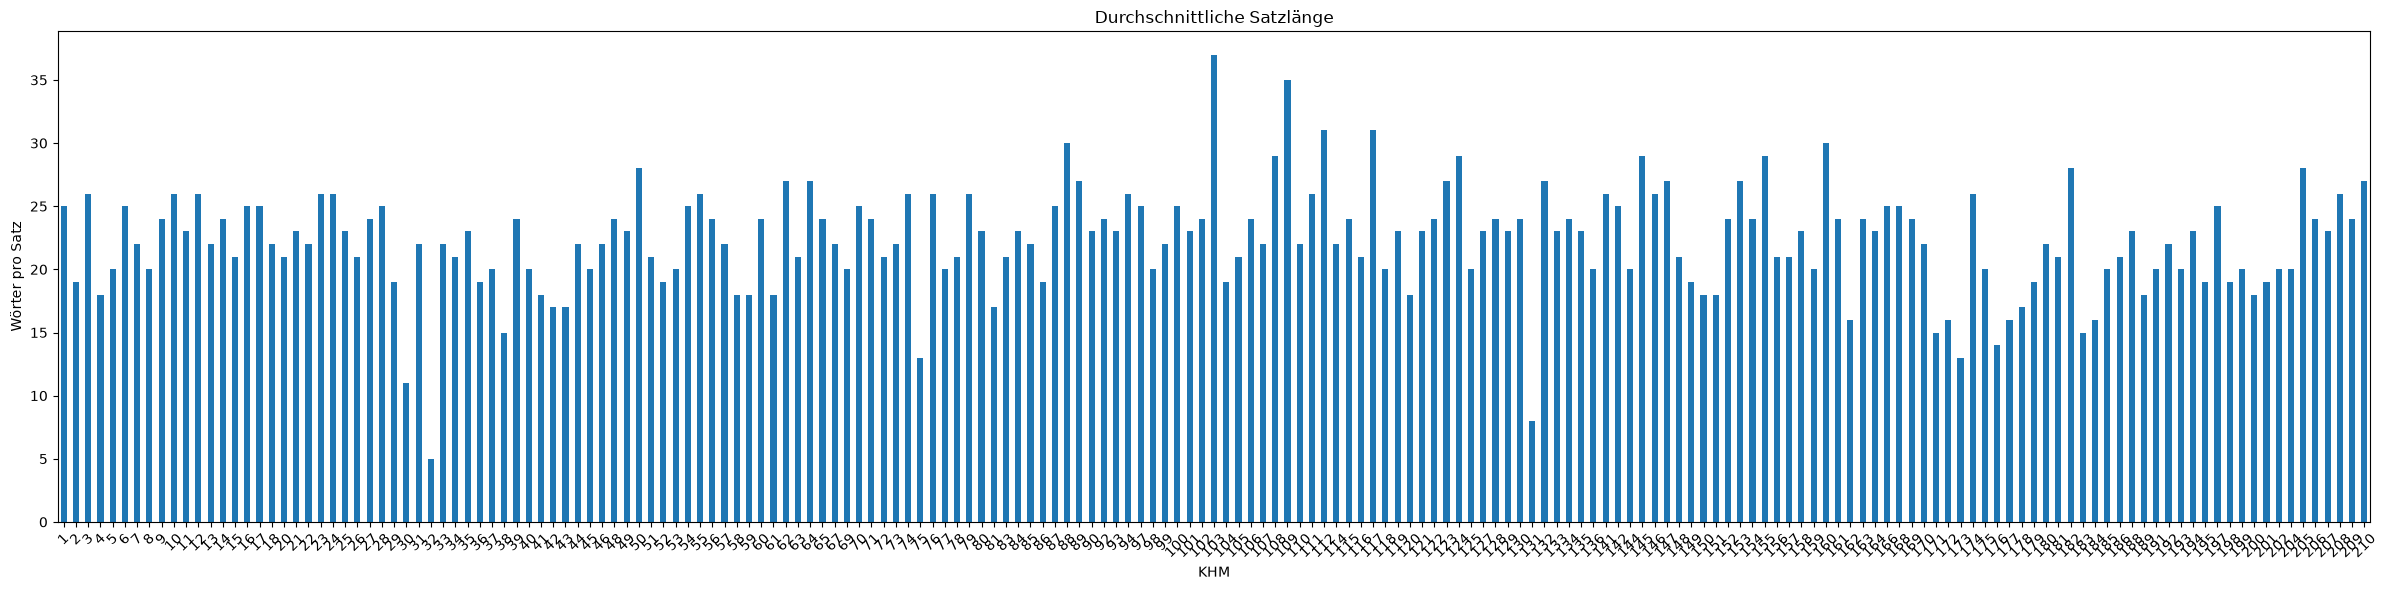

In [44]:
fig, ax = plt.subplots(figsize=(24, 6))

df["mean sentence length"].plot(
    kind="bar",
    ax=ax
)

ax.set_title("Durchschnittliche Satzlänge")
ax.set_xlabel("KHM")
ax.set_ylabel("Wörter pro Satz")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Labels

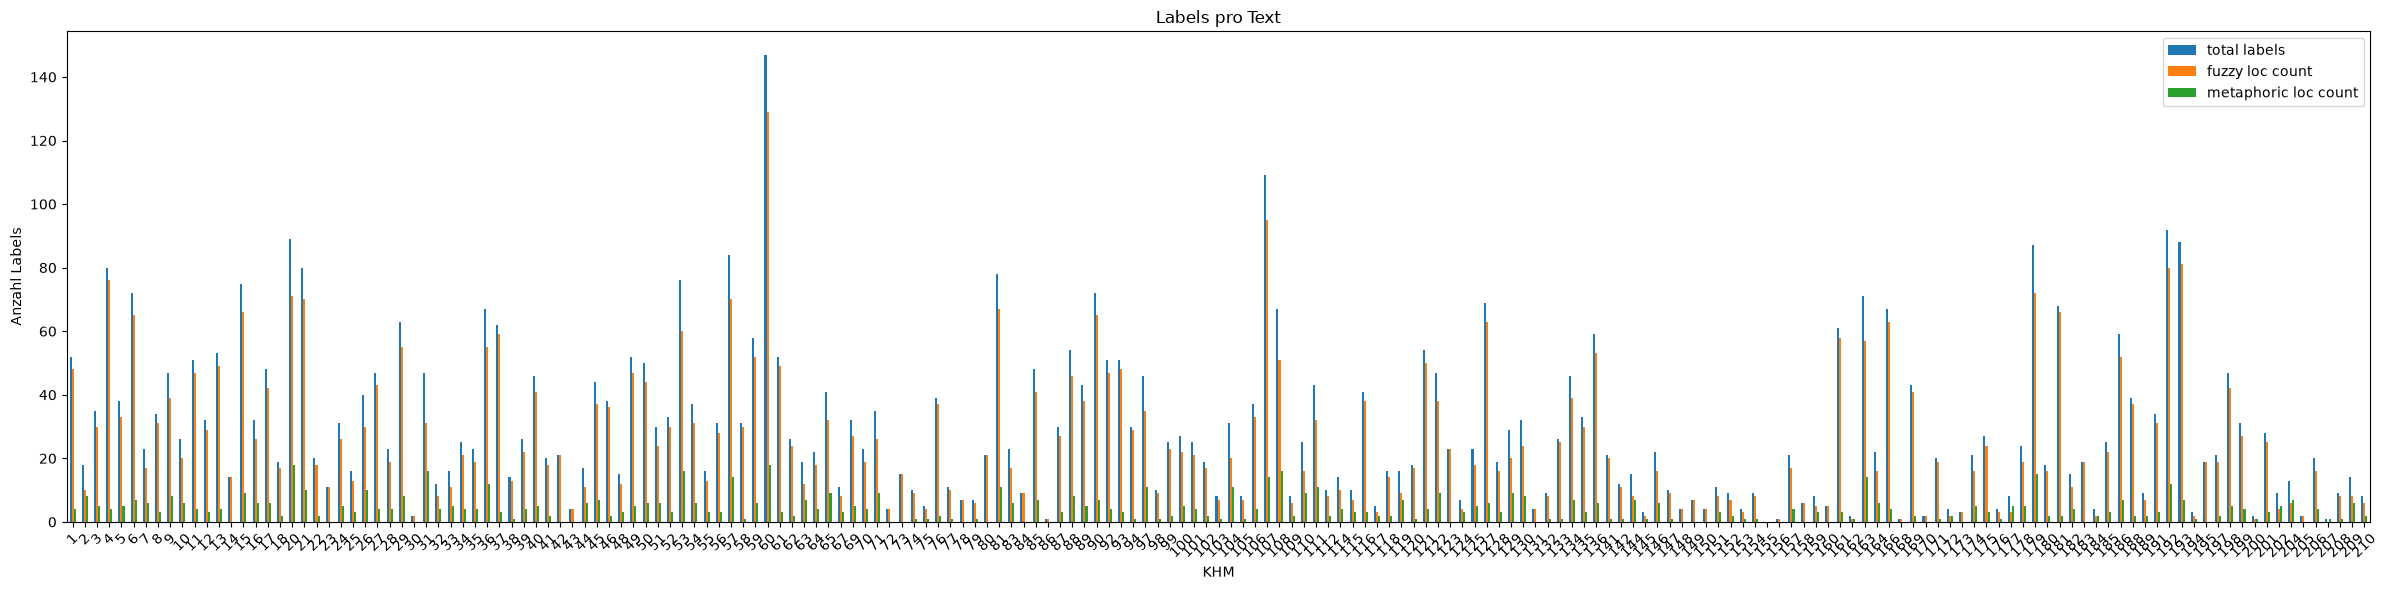

In [45]:
fig, ax = plt.subplots(figsize=(24, 6))

df[
    [
        "total labels",
        "fuzzy loc count",
        "metaphoric loc count",
    ]
].plot(
    kind="bar",
    ax=ax
)

ax.set_title("Labels pro Text")
ax.set_xlabel("KHM")
ax.set_ylabel("Anzahl Labels")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## BiLSTM vs RoBERTa

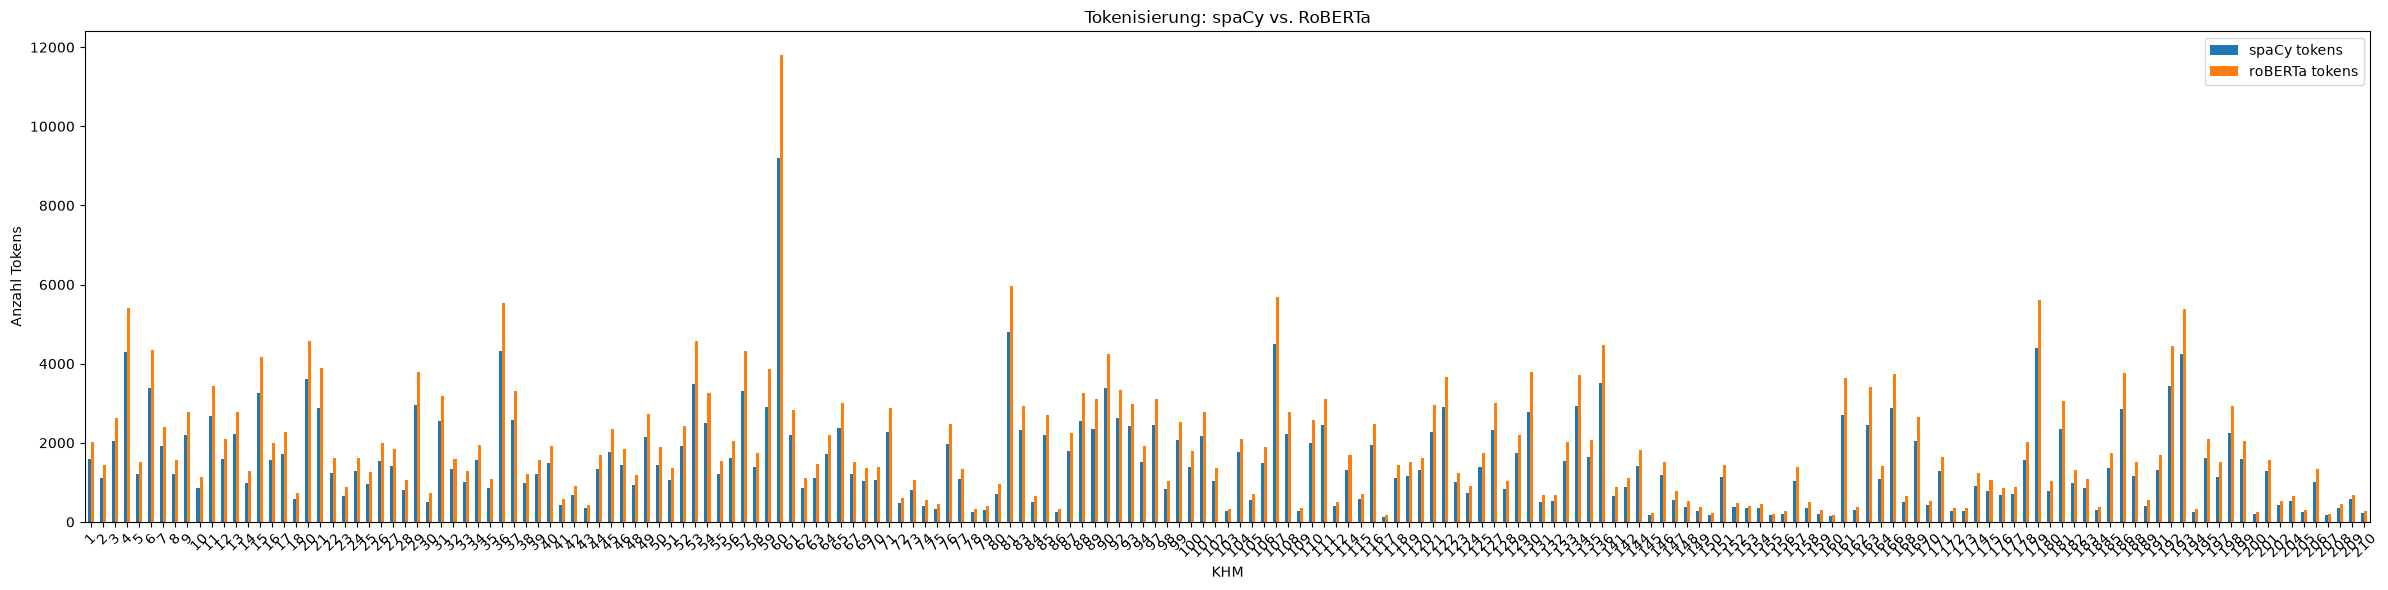

In [46]:
fig, ax = plt.subplots(figsize=(24, 6))

df[
    ["spaCy tokens", "roBERTa tokens"]
].plot(
    kind="bar",
    ax=ax
)

ax.set_title("Tokenisierung: spaCy vs. RoBERTa")
ax.set_xlabel("KHM")
ax.set_ylabel("Anzahl Tokens")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Word Count vs Label density

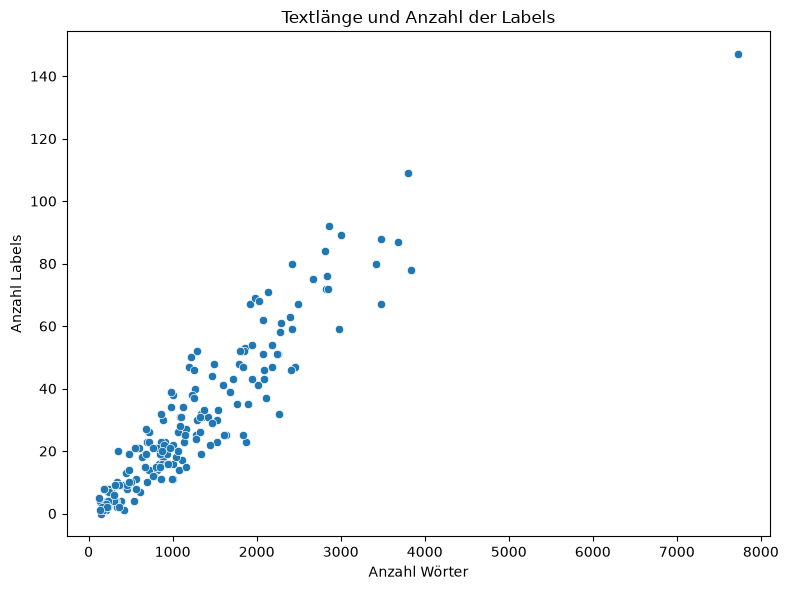

In [47]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="word count",
    y="total labels",
    ax=ax
)

ax.set_title("Textlänge und Anzahl der Labels")
ax.set_xlabel("Anzahl Wörter")
ax.set_ylabel("Anzahl Labels")

plt.tight_layout()
plt.show()



## Sentence length vs labels

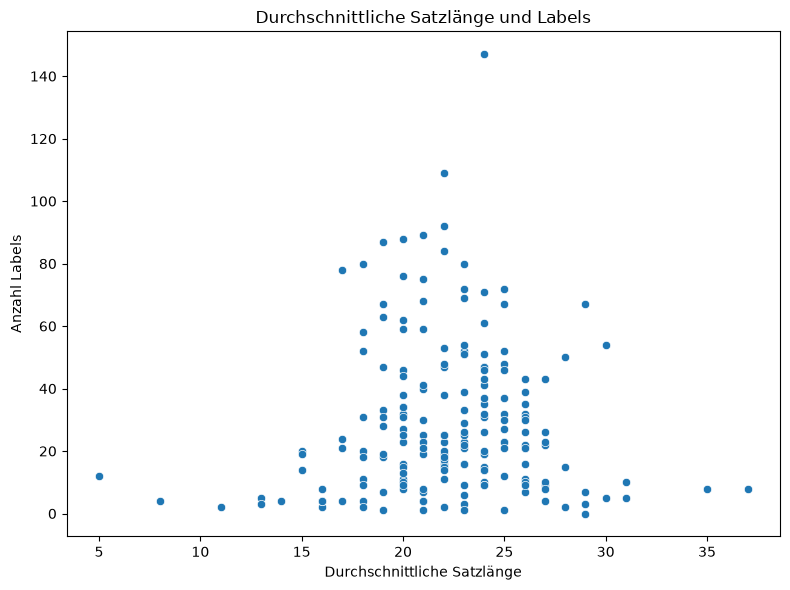

In [48]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="mean sentence length",
    y="total labels",
    ax=ax
)

ax.set_title("Durchschnittliche Satzlänge und Labels")
ax.set_xlabel("Durchschnittliche Satzlänge")
ax.set_ylabel("Anzahl Labels")

plt.tight_layout()
plt.show()

## Label density

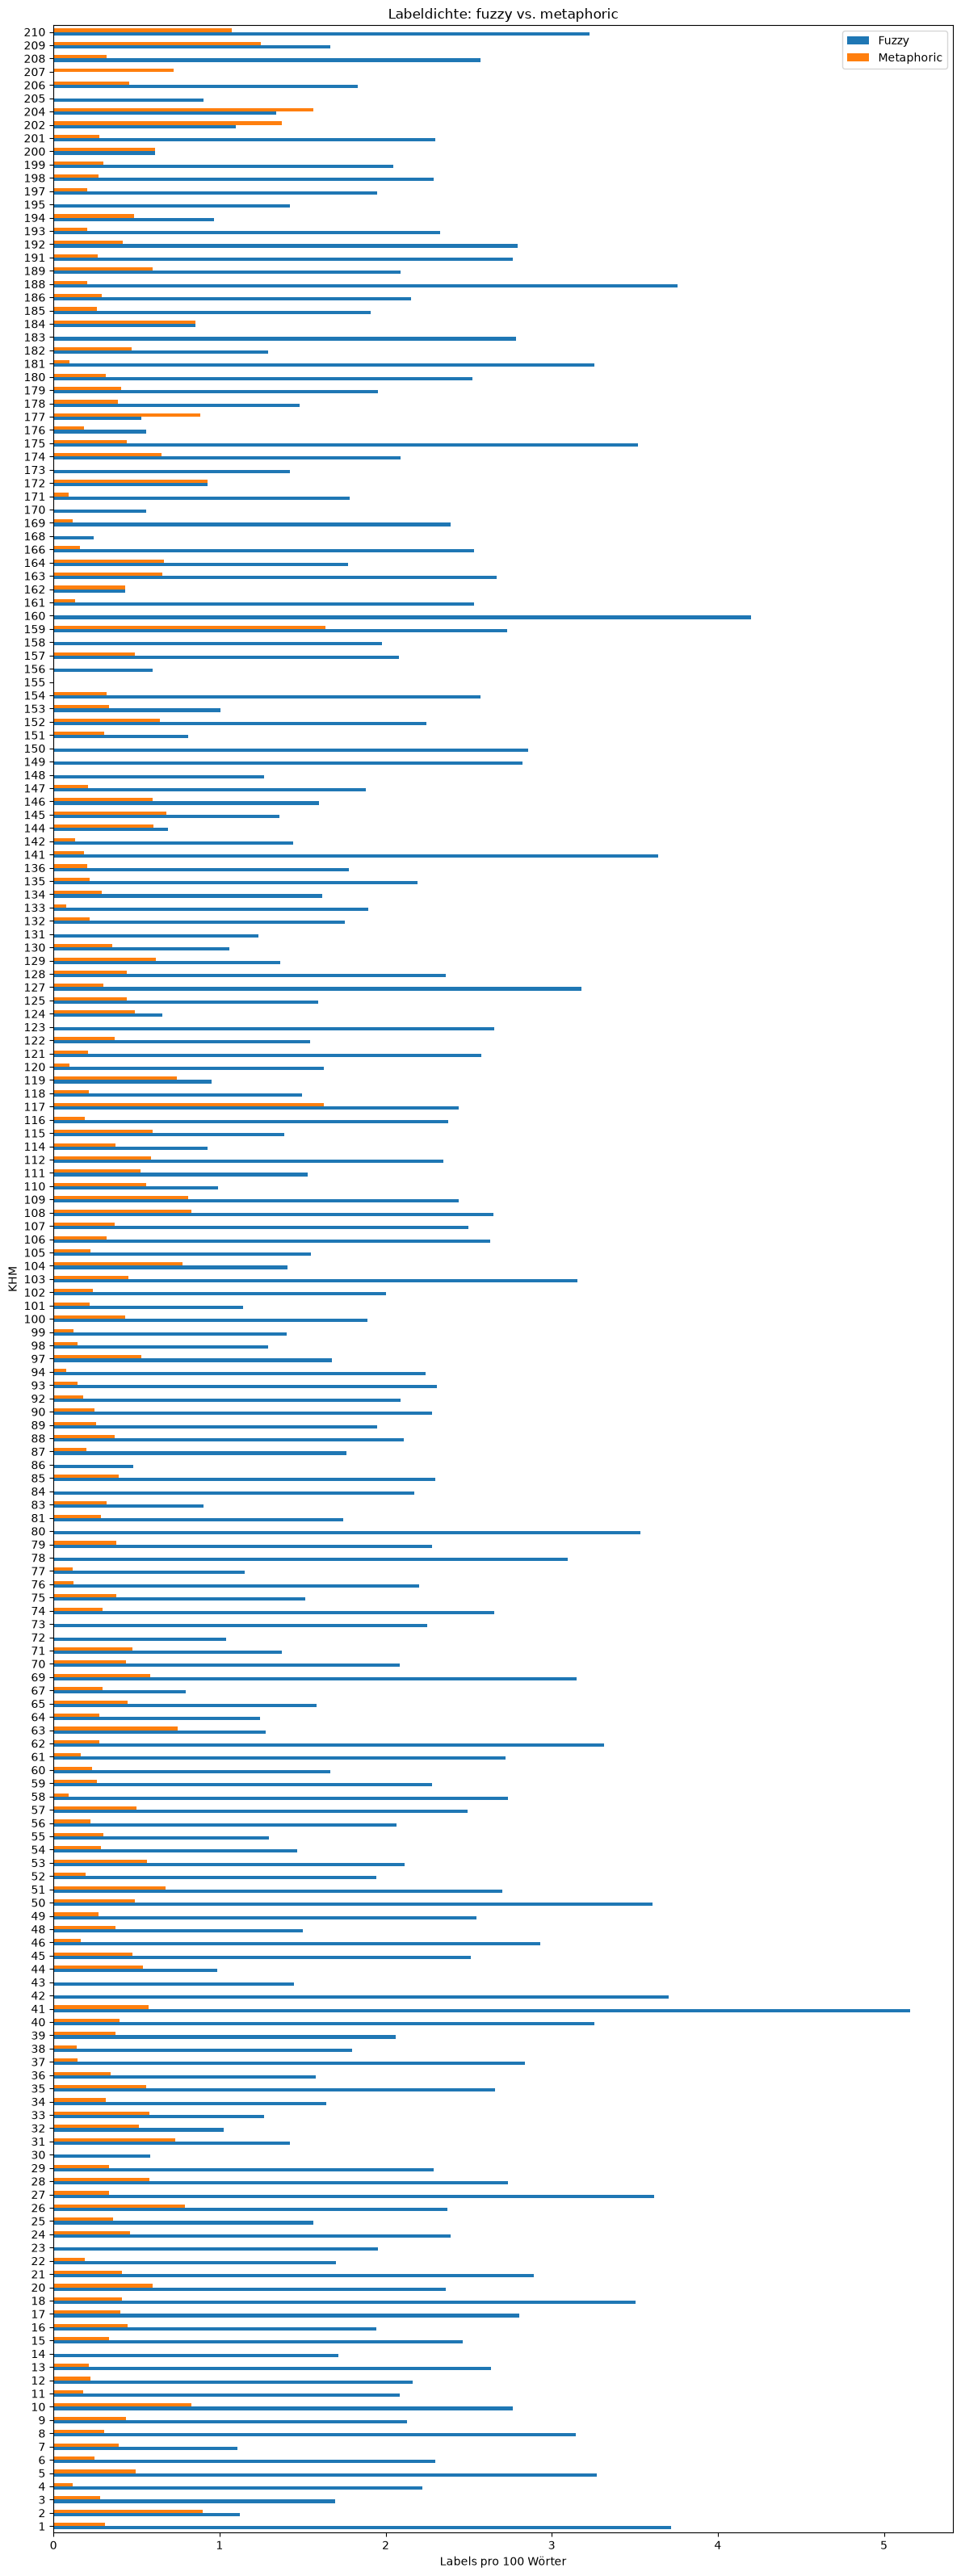

In [49]:
df["fuzzy density"] = (
    df["fuzzy loc count"] / df["word count"] * 100
)

df["metaphoric density"] = (
    df["metaphoric loc count"] / df["word count"] * 100
)


fig, ax = plt.subplots(figsize=(12, 32))

df[
    ["fuzzy density", "metaphoric density"]
].plot(
    kind="barh",
    ax=ax
)

ax.set_title("Labeldichte: fuzzy vs. metaphoric")
ax.set_xlabel("Labels pro 100 Wörter")
ax.set_ylabel("KHM")
ax.legend([
    "Fuzzy",
    "Metaphoric"
])

plt.tight_layout()
plt.show()